# HW1 Problem 2: Self-Attention Layer for Semantic Similarity Scoring

**Student ID:** 315511079
**Submission filename:** `hw1_2_315511079.ipynb`
**Final Kaggle leaderboard score (Pearson): 0.68679**

This notebook is the provided `atten.ipynb`. Following the course announcement, **only the code inside `TODO` / `TODO (Optional)` blocks has been changed**. Markdown cells were added, plus extra cells for the (c) and (d) experiments and for the (e) ensemble. Those extra cells only *call* the provided functions (`TransformerRegressor`, `train_model`, `evaluate_model`) and the builders defined inside the TODO blocks. They do not redefine or alter any provided code.

| Where | What was filled in |
|---|---|
| 9. `MyMultiheadAttention` (TODO) | Q/K/V projections, head split, scaled dot-product attention, key-padding mask, head concatenation, output projection; optional learnable relative-position bias |
| 10. `MyTransformerEncoderLayer` (TODO) | post-LN encoder layer: MHA → dropout → residual → LayerNorm → FFN → dropout → residual → LayerNorm; optional input LayerNorm |
| 11. pooling (TODO Optional) | pooling strategies (`mean`, `anchor_target_mean`, `interact`, `mlp`). The `mlp` strategy's small projection layer is **created inside this TODO (Optional) block**, so no parameters are added anywhere outside TODO code |
| 12. hyperparameters (TODO / TODO Optional) | `NHEAD = 4`; tuned epochs, dropout, weight decay, embedding learning rate, scheduler and pooling choice |
| 14. optimizer / scheduler (TODO / TODO Optional) | AdamW with two parameter groups (20× learning rate for the token embedding); per-epoch linear warm-up + cosine decay |

Fixed settings (unchanged): provided vocabulary procedure, `MAX_LEN = 64`, `EMBEDDING_DIM = 128`, `NUM_LAYERS = 2`, `BATCH_SIZE = 64`, `SEED = 42`, MSE loss. The model is selected by the best validation Pearson, which the provided `train_model` already does.

In [1]:
# 1. Import Packages
import os
import re
import math
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader


In [2]:
# 2. Reproducibility and Device
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


In [3]:
# 3. Read Data
# If you run this notebook on Kaggle, change DATA_DIR if necessary.
DATA_DIR = "/kaggle/input/2026-llm-hw1-2-semantic-similarity-scoring"

train_path = os.path.join(DATA_DIR, "train.csv")
val_path = os.path.join(DATA_DIR, "val.csv")
test_path = os.path.join(DATA_DIR, "test.csv")

# Local fallback
if not os.path.exists(train_path):
    DATA_DIR = "."
    train_path = os.path.join(DATA_DIR, "train.csv")
    val_path = os.path.join(DATA_DIR, "val.csv")
    test_path = os.path.join(DATA_DIR, "test.csv")

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

display(train_df.head())
display(val_df.head())
display(test_df.head())


Train: (25531, 5)
Validation: (3647, 5)
Test: (7295, 4)


,id,anchor,target,context,score
0,808c9edf2bfa8770,gate insulator film,gate insulator thickness,H01,0.50
1,17d1d9d4da553fa5,rotary electric,controller of rotary electric machine,B64,0.50
2,9905ae6440094df0,based method,method of teaching,G01,0.00
3,66766be479f904f2,inner closed,axial,B24,0.25
4,6bcfd7479a107de8,predetermined acceleration,given speed,B66,0.25


,id,anchor,target,context,score
0,af96f2c33e268529,auxiliary water,supplementing water,F24,0.50
1,e028ad0e05f58a48,membrane vesicle,lipid membranes,A61,0.75
2,362c2f8b3decb62a,triethylammonium salt,triethylammonium acetate,C07,0.50
3,1f4cf5caea3b0e65,sensitive photographic,sensitive silver photographic,H01,0.50
4,b640037b4b1cee75,movement directions,directions,B60,0.50


,id,anchor,target,context
0,56c8cc4180a9ea16,return structure,return prevention structure,F27
1,d432a6416712e59a,pressure failure,impact,F02
2,e7ab59f580fd7184,define panel,committee,C02
3,03ab2935bce8a3eb,roll on workpiece,roll on object,B23
4,494f877d48deb27f,arcade,archery game,A63


In [4]:
# 4. Tokenizer and Input Construction

def tokenizer(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9]+", " ", text)
    return text.strip().split()

def tokenize_input(context, anchor, target):
    # Keep the special tokens while tokenizing the remaining text.
    pieces = ["<context>"]
    pieces += tokenizer(context)
    pieces += ["<sep>"]
    pieces += tokenizer(anchor)
    pieces += ["<sep>"]
    pieces += tokenizer(target)
    return pieces


In [5]:
# 5. Build Vocabulary from TRAINING DATA ONLY

def build_vocab(df, min_freq=1):
    counter = Counter()

    for _, row in df.iterrows():
        tokens = tokenize_input(row["context"], row["anchor"], row["target"])
        counter.update(tokens)

    vocab = {
        "<pad>": 0,
        "<unk>": 1,
        "<context>": 2,
        "<sep>": 3,
    }

    for token, freq in counter.items():
        if freq >= min_freq and token not in vocab:
            vocab[token] = len(vocab)

    return vocab

vocab = build_vocab(train_df)
PAD_IDX = vocab["<pad>"]
UNK_IDX = vocab["<unk>"]

print("Vocabulary size:", len(vocab))


Vocabulary size: 7749


In [6]:
# 6. Preprocess Data

MAX_LEN = 64

def encode_example(context, anchor, target, vocab, max_len=MAX_LEN):
    tokens = tokenize_input(context, anchor, target)
    ids = [vocab.get(token, UNK_IDX) for token in tokens]

    ids = ids[:max_len]
    attention_mask = [1] * len(ids)

    pad_len = max_len - len(ids)
    ids += [PAD_IDX] * pad_len
    attention_mask += [0] * pad_len

    return torch.tensor(ids, dtype=torch.long), torch.tensor(attention_mask, dtype=torch.float)

class PatentSimilarityDataset(Dataset):
    def __init__(self, df, vocab, max_len=MAX_LEN, has_labels=True):
        self.df = df.reset_index(drop=True)
        self.vocab = vocab
        self.max_len = max_len
        self.has_labels = has_labels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        input_ids, attention_mask = encode_example(
            row["context"],
            row["anchor"],
            row["target"],
            self.vocab,
            self.max_len,
        )

        item = {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "id": row["id"],
        }

        if self.has_labels:
            item["score"] = torch.tensor(float(row["score"]), dtype=torch.float)

        return item


In [7]:
# 7. Create DataLoaders

BATCH_SIZE = 64

train_dataset = PatentSimilarityDataset(train_df, vocab, has_labels=True)
val_dataset = PatentSimilarityDataset(val_df, vocab, has_labels=True)
test_dataset = PatentSimilarityDataset(test_df, vocab, has_labels=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

batch = next(iter(train_loader))
print("input_ids:", batch["input_ids"].shape)
print("attention_mask:", batch["attention_mask"].shape)
print("score:", batch["score"].shape)


input_ids: torch.Size([64, 64])
attention_mask: torch.Size([64, 64])
score: torch.Size([64])


In [8]:
# 8. Positional Encoding

class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 5000):
        super().__init__()

        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


In [9]:
# 9. Multi-head Attention

class MyMultiheadAttention(nn.Module):
    # ----- TODO ----- #
    # Implement Multi-head Self-Attention.
    #
    # Your implementation should include:
    # 1. Query, Key, and Value projections
    # 2. Split the projected representations into multiple attention heads
    # 3. Scaled dot-product attention
    # 4. Padding-mask handling
    # 5. Concatenation of all attention heads
    # 6. Final output projection
    #
    # Please study the Transformer paper:
    # https://arxiv.org/pdf/1706.03762
    #
    # Do NOT use torch.nn.MultiheadAttention.
    def __init__(self, d_model, nhead, dropout=0.1):
        super().__init__()
        assert d_model % nhead == 0, "d_model must be divisible by nhead"
        self.d_model = d_model
        self.nhead = nhead
        self.head_dim = d_model // nhead

        # 1. Query, Key, and Value projections (+ 6. output projection)
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.attn_dropout = nn.Dropout(dropout)

        # Learnable relative-position bias (one scalar per head and per relative
        # distance j - i, as in Shaw et al. 2018 / T5). The provided embedding is
        # N(0,1) * sqrt(d_model) ~ 11x larger than the sinusoidal encoding, so the
        # absolute position signal is weak; this bias gives attention a direct,
        # scale-independent position (and segment-boundary) signal.
        self.use_rel_pos = globals().get("USE_REL_POS_BIAS", True)
        self.max_rel = MAX_LEN - 1
        if self.use_rel_pos:
            self.rel_pos_bias = nn.Parameter(torch.zeros(nhead, 2 * self.max_rel + 1))

    def split_heads(self, x):
        # 2. (B, L, D) -> (B, H, L, D/H)
        B, L, _ = x.shape
        return x.view(B, L, self.nhead, self.head_dim).transpose(1, 2)

    def merge_heads(self, x):
        # 5. Concatenate all heads: (B, H, L, D/H) -> (B, L, D)
        B, H, L, Dh = x.shape
        return x.transpose(1, 2).contiguous().view(B, L, H * Dh)

    def forward(self, x, attention_mask=None):
        q = self.split_heads(self.q_proj(x))
        k = self.split_heads(self.k_proj(x))
        v = self.split_heads(self.v_proj(x))

        # 3. Scaled dot-product attention: softmax(QK^T / sqrt(d_k)) V
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        if self.use_rel_pos:
            L = x.size(1)
            pos = torch.arange(L, device=x.device)
            rel = (pos[None, :] - pos[:, None]).clamp(-self.max_rel, self.max_rel) + self.max_rel
            scores = scores + self.rel_pos_bias[:, rel].unsqueeze(0)     # (1, H, L, L)

        # 4. Padding mask: padded positions can never be attended to as keys
        if attention_mask is not None:
            key_mask = attention_mask[:, None, None, :].bool()      # (B, 1, 1, L)
            scores = scores.masked_fill(~key_mask, -1e9)

        attn = torch.softmax(scores, dim=-1)
        attn = self.attn_dropout(attn)
        context = torch.matmul(attn, v)                              # (B, H, L, D/H)

        # 5. + 6. concatenate heads, then the final output projection
        return self.out_proj(self.merge_heads(context))
    # ----- TODO ----- #


In [10]:
# 10. Transformer Encoder Layer

class MyTransformerEncoderLayer(nn.Module):
    # ----- TODO ----- #
    # Implement one Transformer Encoder Layer.
    #
    # Your implementation should include:
    # 1. Multi-head self-attention using MyMultiheadAttention
    # 2. Residual connection after self-attention
    # 3. Layer normalization
    # 4. Position-wise feed-forward network
    # 5. Residual connection after the feed-forward network
    # 6. Layer normalization
    # 7. Dropout
    #
    # Please study the Transformer paper:
    # https://arxiv.org/pdf/1706.03762
    def __init__(self, d_model, nhead, dim_feedforward=256, dropout=0.2):
        super().__init__()
        # 1. Multi-head self-attention
        self.self_attn = MyMultiheadAttention(d_model, nhead, dropout=dropout)

        # 4. Position-wise feed-forward network: Linear -> ReLU -> Dropout -> Linear
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, dim_feedforward),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(dim_feedforward, d_model),
        )

        # 3. / 6. Layer normalization
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

        # 7. Dropout on each sub-layer output
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

        # Input LayerNorm. The layer input of the first layer is
        # Embedding * sqrt(d_model) with Embedding ~ N(0, 1), i.e. about 11 per
        # dimension, while the attention output is about 1 per dimension. Without
        # normalising the input, x + Attn(x) is dominated by x and the first
        # attention sub-layer has almost no effect.
        self.use_input_norm = globals().get("USE_INPUT_LAYERNORM", True)
        if self.use_input_norm:
            self.norm0 = nn.LayerNorm(d_model)

    def forward(self, x, attention_mask=None):
        if self.use_input_norm:
            x = self.norm0(x)
        # Post-LN, as in the original Transformer: x = LayerNorm(x + Dropout(Sublayer(x)))
        # 1. + 2. + 3. self-attention -> residual connection -> layer norm
        attn_out = self.self_attn(x, attention_mask)
        x = self.norm1(x + self.dropout1(attn_out))

        # 4. + 5. + 6. feed-forward -> residual connection -> layer norm
        ff_out = self.feed_forward(x)
        x = self.norm2(x + self.dropout2(ff_out))
        return x
    # ----- TODO ----- #


## Model design

* **Multi-head attention.** $Q=XW_Q,\;K=XW_K,\;V=XW_V$ are each split into $h$ heads of size $d_k = 128/h$. Each head computes $\mathrm{softmax}(QK^\top/\sqrt{d_k})V$. Padded **key** positions get a score of $-10^9$, so no token attends to padding. The heads are concatenated and passed through $W_O$.
* **Relative-position bias** (inside `MyMultiheadAttention`; implemented and tested in (d), switched off in the final model): a learnable scalar $b_{h,\,j-i}$ per head and per relative distance is added to the attention scores (Shaw et al., 2018; T5). The provided embedding is $\mathcal N(0,1)\cdot\sqrt{128}\approx 11$ per dimension, against $\le 1$ for the sinusoidal encoding, so the absolute position signal is weak. The bias gives attention a scale-independent position signal and lets tokens locate the `<sep>` boundaries.
* **Input LayerNorm** (inside `MyTransformerEncoderLayer`): the layer input is normalised first. Otherwise, in the first layer $x + \mathrm{Attn}(x)$ is dominated by the ≈11× larger embedding and the attention sub-layer barely changes the representation.
* **Embedding learning rate** (optimizer, Section 14): the token embedding is trained with 20× the base learning rate in its own AdamW parameter group. Its weights are $\mathcal N(0,1)$, so with lr $10^{-3}$ an Adam step moves them by only about 0.1%, while the embedding table holds most of the model's parameters.
* **Encoder layer** (post-LN, as in Vaswani et al.): $x \leftarrow \mathrm{LN}(x + \mathrm{Drop}(\mathrm{MHA}(x)))$, then $x \leftarrow \mathrm{LN}(x + \mathrm{Drop}(\mathrm{FFN}(x)))$, with $\mathrm{FFN} = \mathrm{Linear}\to\mathrm{ReLU}\to\mathrm{Dropout}\to\mathrm{Linear}$.
* **Pooling** (TODO Optional). Anchor and target positions are recovered from `input_ids` alone: `cumsum(input_ids == <sep>)` is 0 for context, 1 for anchor and 2 for target. `interact` pooling computes the masked means $g$ (whole sequence), $u$ (anchor words) and $v$ (target words). It then builds a 128-dim vector from three disjoint slices: $g$ (32 dims, context summary), $u\odot v$ (48 dims, alignment) and $|u-v|$ (48 dims, difference). The provided `regression_head = Linear(128, 1)` is reused unchanged, so no learnable parameters are added. Because the encoder is trained end-to-end, it learns to place the useful information in the dimensions each slice uses.
* **`mlp` pooling (final).** Same $g, u, v$, but the full vector $[g, u, v, |u-v|, u\odot v] \in \mathbb R^{640}$ goes through $\mathrm{Linear}(640\to128)\to\mathrm{GELU}\to\mathrm{Dropout}$ and then into the provided `regression_head`. The projection is created inside the pooling `TODO (Optional)` block on the first forward pass. The optimizer `TODO` block runs one dummy forward pass before building the optimizer, so these parameters are trained, and no code outside TODO blocks is changed.

In [11]:
# 11. Transformer Regressor

class TransformerRegressor(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        pad_idx,
        nhead=4,
        num_layers=2,
        dim_feedforward=256,
        dropout=0.2,
        max_len=MAX_LEN,
    ):
        super().__init__()

        self.pad_idx = pad_idx
        self.d_model = embedding_dim

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_idx
        )

        self.pos_encoder = PositionalEncoding(
            d_model=embedding_dim,
            max_len=max_len
        )

        self.dropout = nn.Dropout(dropout)

        self.encoder_layers = nn.ModuleList([
            MyTransformerEncoderLayer(
                d_model=embedding_dim,
                nhead=nhead,
                dim_feedforward=dim_feedforward,
                dropout=dropout,
            )
            for _ in range(num_layers)
        ])

        self.regression_head = nn.Linear(embedding_dim, 1)

    def masked_mean_pooling(self, x, attention_mask):
        mask = attention_mask.unsqueeze(-1)
        x = x * mask
        summed = x.sum(dim=1)
        counts = mask.sum(dim=1).clamp(min=1e-9)
        return summed / counts

    def forward(self, input_ids, attention_mask):
        x = self.embedding(input_ids) * math.sqrt(self.d_model)
        x = self.pos_encoder(x)
        x = self.dropout(x)

        for layer in self.encoder_layers:
            x = layer(x, attention_mask)

        # ----- TODO (Optional) ----- #
        # Modify the pooling strategy to improve model performance.
        # The default setting uses masked mean pooling.
        #
        # Every strategy outputs a vector of size embedding_dim, so the
        # provided regression_head = nn.Linear(embedding_dim, 1) is reused.
        # All strategies except "mlp" are parameter-free; the "mlp" projection
        # is created inside this block (see below).
        #   "mean"               : masked mean over all tokens (default)
        #   "anchor_target_mean" : masked mean over anchor + target words only
        #   "interact"           : g = mean(all), u = mean(anchor), v = mean(target);
        #                          pooled = [ g[:k1] , (u*v)[k1:k2] , |u-v|[k2:] ]
        #   "mlp" (final)        : [g, u, v, |u-v|, u*v] -> Linear(5d, d) -> GELU -> Dropout
        # The anchor/target positions are recovered from input_ids alone:
        #   <context> ctx... <sep> anchor... <sep> target...
        # so cumsum(input_ids == <sep>) is 0 / 1 / 2 for context / anchor / target.
        # The strategy comes from POOLING_STRATEGY (set in the hyperparameter
        # cell); an experiment may override it per model via model.pooling_strategy.
        strategy = getattr(self, "pooling_strategy", globals().get("POOLING_STRATEGY", "mean"))
        if strategy == "mean":
            pooled = self.masked_mean_pooling(x, attention_mask)
        else:
            is_sep = input_ids == vocab["<sep>"]
            is_ctx = input_ids == vocab["<context>"]
            segment = is_sep.long().cumsum(dim=1)                    # 0 ctx, 1 anchor, 2 target
            word = attention_mask * (~is_sep).float() * (~is_ctx).float()
            anchor_mask = word * (segment == 1).float()
            target_mask = word * (segment == 2).float()
            d = x.size(-1)
            g = self.masked_mean_pooling(x, attention_mask)
            u = self.masked_mean_pooling(x, anchor_mask)
            v = self.masked_mean_pooling(x, target_mask)
            if strategy == "anchor_target_mean":
                pooled = self.masked_mean_pooling(x, anchor_mask + target_mask)
            elif strategy == "interact":
                k1 = d // 4                       # 32 dims: global summary (context information)
                k2 = k1 + (d - k1) // 2           # 48 dims: alignment u*v, 48 dims: difference |u-v|
                pooled = torch.cat([g[:, :k1], (u * v)[:, k1:k2], (u - v).abs()[:, k2:]], dim=-1)
            elif strategy == "mlp":
                # Interaction features [g, u, v, |u-v|, u*v] (5 x d) followed by a
                # small learnable projection Linear(5d -> d) + GELU + Dropout.
                # The projection is created HERE, inside this TODO (Optional)
                # block, the first time the pooling runs (build_optimizer() in the
                # optimizer TODO block runs one dummy forward pass, so the
                # parameters exist before the optimizer is built). The provided
                # regression_head = Linear(d, 1) then maps the d-dim vector to the score.
                #
                # The feature list is POOL_MLP_FEATURES (hyperparameter cell), or a
                # per-model override in model.pool_mlp_features. Available features
                # (each d-dim):
                #   g, u, v   : mean of all / anchor / target tokens
                #   ad, uv    : |u - v| and u * v
                #   am, adf   : token-level soft alignment (ESIM-style): every anchor
                #               token attends to the target tokens with
                #               softmax(x_i . x_j / sqrt(d)) and vice versa;
                #               am = mean(x_i * aligned_i), adf = mean(|x_i - aligned_i|)
                #   umax, vmax: masked max pooling over anchor / target tokens
                names = getattr(self, "pool_mlp_features",
                                globals().get("POOL_MLP_FEATURES", ["g", "u", "v", "ad", "uv"]))
                fd = {"g": g, "u": u, "v": v, "ad": (u - v).abs(), "uv": u * v}
                if "am" in names or "adf" in names:
                    sim = torch.matmul(x, x.transpose(1, 2)) / math.sqrt(d)      # (B, L, L)
                    def align(row_mask, col_mask):
                        z = sim.masked_fill(~col_mask.bool()[:, None, :], -1e9)
                        aligned = torch.matmul(torch.softmax(z, dim=-1), x)      # (B, L, d)
                        w = (row_mask / row_mask.sum(1, keepdim=True).clamp(min=1e-9)).unsqueeze(-1)
                        return (w * x * aligned).sum(1), (w * (x - aligned).abs()).sum(1)
                    m_a, d_a = align(anchor_mask, target_mask)
                    m_t, d_t = align(target_mask, anchor_mask)
                    fd["am"] = 0.5 * (m_a + m_t)
                    fd["adf"] = 0.5 * (d_a + d_t)
                if "umax" in names or "vmax" in names:
                    def masked_max(m):
                        z = x.masked_fill(~m.bool().unsqueeze(-1), -1e9).max(dim=1).values
                        has = m.sum(1, keepdim=True) > 0
                        return torch.where(has, z, torch.zeros_like(z))
                    fd["umax"] = masked_max(anchor_mask)
                    fd["vmax"] = masked_max(target_mask)
                feats = torch.cat([fd[n] for n in names], dim=-1)
                if not hasattr(self, "pooling_mlp"):
                    self.pooling_mlp = nn.Sequential(
                        nn.Linear(len(names) * d, d), nn.GELU(), nn.Dropout(self.dropout.p)
                    ).to(x.device)
                pooled = self.pooling_mlp(feats)
            elif strategy.startswith("feats:"):
                # "feats:g,uv,ad,am,adf": the d dimensions are split into equal
                # slices, one per listed feature (still parameter-free).
                #   g / u / v : mean of all / anchor / target tokens
                #   uv, ad    : u * v and |u - v|
                #   am, adf   : token-level soft alignment (ESIM-style). Each anchor
                #               token attends to the target tokens with
                #               softmax(x_i . x_j / sqrt(d)) and vice versa; am is the
                #               mean of x_i * aligned_i and adf the mean of
                #               |x_i - aligned_i|, averaged over both directions.
                names = strategy[len("feats:"):].split(",")
                feats = {"g": g, "u": u, "v": v, "uv": u * v, "ad": (u - v).abs()}
                if "am" in names or "adf" in names:
                    sim = torch.matmul(x, x.transpose(1, 2)) / math.sqrt(d)      # (B, L, L)
                    def align(row_mask, col_mask):
                        z = sim.masked_fill(~col_mask.bool()[:, None, :], -1e9)
                        aligned = torch.matmul(torch.softmax(z, dim=-1), x)      # (B, L, d)
                        w = (row_mask / row_mask.sum(1, keepdim=True).clamp(min=1e-9)).unsqueeze(-1)
                        return (w * x * aligned).sum(1), (w * (x - aligned).abs()).sum(1)
                    m_a, d_a = align(anchor_mask, target_mask)
                    m_t, d_t = align(target_mask, anchor_mask)
                    feats["am"] = 0.5 * (m_a + m_t)
                    feats["adf"] = 0.5 * (d_a + d_t)
                bounds = [round(i * d / len(names)) for i in range(len(names) + 1)]
                pooled = torch.cat([feats[n][:, bounds[i]:bounds[i + 1]] for i, n in enumerate(names)], dim=-1)
            else:
                raise ValueError(f"Unknown pooling strategy: {strategy}")
        # ----- TODO (Optional) ----- #

        logits = self.regression_head(pooled).squeeze(-1)

        # Constrain predictions to (0, 1)
        return torch.sigmoid(logits)


In [12]:
# 12. Define Hyperparameters

# Fixed settings
EMBEDDING_DIM = 128
NUM_LAYERS = 2

# ----- TODO ----- #
# Use NHEAD = 4 for the main experiment.
# Then compare NHEAD = 1, 4, and 8 using the same data split
# and training budget.
NHEAD = 4
# ----- TODO ----- #

# ----- TODO (Optional) ----- #
# Tune these hyperparameters to improve validation
# Pearson correlation. Document every modification you make.
# Final setting (configuration D10 in Section (d)):
#   EPOCHS 10 -> 25, weight decay 1e-4 -> 1e-2,
#   2-epoch linear warm-up + cosine decay scheduler,
#   "mlp" pooling ([g, u, v, |u-v|, u*v] -> Linear -> GELU, defined in the pooling TODO block),
#   input LayerNorm in each encoder layer,
#   20x learning rate for the token embedding,
#   dropout 0.2 -> 0.1.
#   (relative-position bias was tried in D4 / D7 and is not used)
USE_INPUT_LAYERNORM = True        # read by MyTransformerEncoderLayer (Section 10)
USE_REL_POS_BIAS = False          # read by MyMultiheadAttention (Section 9)
DIM_FEEDFORWARD = 256
DROPOUT = 0.1                     # 0.2 -> 0.1 (configuration D9)
LEARNING_RATE = 1e-3
EPOCHS = 25
WEIGHT_DECAY = 1e-2               # used by the AdamW optimizer (Section 14)
EMB_LR_MULT = 20.0                # learning-rate multiplier for the token embedding (Section 14)
SCHEDULER_TYPE = "warmup_cosine"  # "none" | "plateau" | "warmup_cosine"
WARMUP_EPOCHS = 2
POOLING_STRATEGY = "mlp"          # "mean" | "anchor_target_mean" | "interact" | "mlp" | "feats:..."
POOL_MLP_FEATURES = ["g", "u", "v", "ad", "uv"]   # inputs of the "mlp" pooling; options also: "am", "adf", "umax", "vmax"
# ----- TODO (Optional) ----- #

assert EMBEDDING_DIM % NHEAD == 0

model = TransformerRegressor(
    vocab_size=len(vocab),
    embedding_dim=EMBEDDING_DIM,
    pad_idx=PAD_IDX,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT,
    max_len=MAX_LEN,
).to(device)

print(model)


TransformerRegressor(
  (embedding): Embedding(7749, 128, padding_idx=0)
  (pos_encoder): PositionalEncoding()
  (dropout): Dropout(p=0.1, inplace=False)
  (encoder_layers): ModuleList(
    (0-1): 2 x MyTransformerEncoderLayer(
      (self_attn): MyMultiheadAttention(
        (q_proj): Linear(in_features=128, out_features=128, bias=True)
        (k_proj): Linear(in_features=128, out_features=128, bias=True)
        (v_proj): Linear(in_features=128, out_features=128, bias=True)
        (out_proj): Linear(in_features=128, out_features=128, bias=True)
        (attn_dropout): Dropout(p=0.1, inplace=False)
      )
      (feed_forward): Sequential(
        (0): Linear(in_features=128, out_features=256, bias=True)
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): Linear(in_features=256, out_features=128, bias=True)
      )
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (d

In [13]:
# 13. Evaluation Metrics

def pearson_corr(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)

    if np.std(y_true) == 0 or np.std(y_pred) == 0:
        return 0.0

    return float(np.corrcoef(y_true, y_pred)[0, 1])

def rmse(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


In [14]:
# 14. Define Loss Function and Optimizer

criterion = nn.MSELoss()

# ----- TODO ----- #
# Choose an optimizer and set its hyperparameters.
# You may consider Adam, AdamW, SGD, etc.
def build_optimizer(model, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY, emb_lr_mult=None, emb_weight_decay=None):
    # AdamW: Adam with decoupled weight decay.
    # Two parameter groups: the token embedding gets a larger learning rate
    # (EMB_LR_MULT x lr). Its weights are ~N(0, 1), so with lr = 1e-3 each Adam
    # step changes them by only ~0.1%, and the embedding table (about 1M of the
    # model's parameters) would learn far more slowly than the rest of the model.
    if emb_lr_mult is None:
        emb_lr_mult = EMB_LR_MULT
    if emb_weight_decay is None:
        emb_weight_decay = globals().get("EMB_WEIGHT_DECAY", weight_decay)
    # The "mlp" pooling strategy creates its learnable projection lazily inside
    # the pooling TODO block. Run one dummy forward pass so that those
    # parameters exist before the optimizer collects the model's parameters.
    device_ = next(model.parameters()).device
    was_training = model.training
    model.eval()
    with torch.no_grad():
        dummy_ids = torch.tensor([[vocab["<context>"], vocab["<sep>"], UNK_IDX, vocab["<sep>"], UNK_IDX]], device=device_)
        model(dummy_ids, torch.ones_like(dummy_ids, dtype=torch.float))
    model.train(was_training)
    emb_params = [model.embedding.weight]
    other_params = [p for n, p in model.named_parameters() if n != "embedding.weight"]
    return optim.AdamW(
        [{"params": other_params, "lr": lr},
         {"params": emb_params, "lr": lr * emb_lr_mult, "weight_decay": emb_weight_decay}],
        lr=lr, weight_decay=weight_decay,
    )

optimizer = build_optimizer(model)
# ----- TODO ----- #

# ----- TODO (Optional) ----- #
# Use a learning-rate scheduler to improve performance.
# train_model() calls scheduler.step() once per epoch
# (ReduceLROnPlateau receives the validation loss), so every schedule is per epoch.
def build_scheduler(optimizer, kind=SCHEDULER_TYPE, epochs=EPOCHS, warmup_epochs=WARMUP_EPOCHS):
    if kind in (None, "none"):
        return None
    if kind == "plateau":
        return optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)
    if kind == "warmup_cosine":
        def lr_lambda(epoch):  # epoch = number of completed epochs
            if epoch < warmup_epochs:
                return (epoch + 1) / warmup_epochs                    # linear warm-up
            progress = (epoch - warmup_epochs) / max(1, epochs - warmup_epochs)
            return 0.5 * (1.0 + math.cos(math.pi * progress))      # cosine decay
        return optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    raise ValueError(f"Unknown scheduler: {kind}")

scheduler = build_scheduler(optimizer)
# ----- TODO (Optional) ----- #

In [15]:
# 15. Training and Validation Functions

def evaluate_model(model, data_loader, criterion):
    model.eval()

    losses = []
    all_scores = []
    all_predictions = []

    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            scores = batch["score"].to(device)

            predictions = model(input_ids, attention_mask)
            loss = criterion(predictions, scores)

            losses.append(loss.item())
            all_scores.extend(scores.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    val_loss = float(np.mean(losses))
    val_pearson = pearson_corr(all_scores, all_predictions)
    val_rmse = rmse(all_scores, all_predictions)

    return val_loss, val_pearson, val_rmse


def train_model(model, train_loader, val_loader, criterion, optimizer, epochs, scheduler=None):
    history = {
        "train_loss": [],
        "val_loss": [],
        "val_pearson": [],
        "val_rmse": [],
    }

    best_pearson = -float("inf")
    best_state = None

    for epoch in range(epochs):
        model.train()
        batch_losses = []

        for batch in train_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            scores = batch["score"].to(device)

            optimizer.zero_grad()

            predictions = model(input_ids, attention_mask)
            loss = criterion(predictions, scores)

            loss.backward()
            optimizer.step()

            batch_losses.append(loss.item())

        train_loss = float(np.mean(batch_losses))
        val_loss, val_pearson, val_rmse_value = evaluate_model(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_pearson"].append(val_pearson)
        history["val_rmse"].append(val_rmse_value)

        if scheduler is not None:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()

        if val_pearson > best_pearson:
            best_pearson = val_pearson
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Pearson: {val_pearson:.4f} | "
            f"Val RMSE: {val_rmse_value:.4f}"
        )

    if best_state is not None:
        model.load_state_dict(best_state)

    return history


In [16]:
# 16. Train Model

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=EPOCHS,
    scheduler=scheduler,
)


Epoch 01/25 | Train Loss: 0.0558 | Val Loss: 0.0520 | Val Pearson: 0.4819 | Val RMSE: 0.2280
Epoch 02/25 | Train Loss: 0.0417 | Val Loss: 0.0495 | Val Pearson: 0.5496 | Val RMSE: 0.2225
Epoch 03/25 | Train Loss: 0.0272 | Val Loss: 0.0516 | Val Pearson: 0.5787 | Val RMSE: 0.2272
Epoch 04/25 | Train Loss: 0.0197 | Val Loss: 0.0479 | Val Pearson: 0.5891 | Val RMSE: 0.2189
Epoch 05/25 | Train Loss: 0.0155 | Val Loss: 0.0494 | Val Pearson: 0.5936 | Val RMSE: 0.2222
Epoch 06/25 | Train Loss: 0.0131 | Val Loss: 0.0490 | Val Pearson: 0.6031 | Val RMSE: 0.2213
Epoch 07/25 | Train Loss: 0.0112 | Val Loss: 0.0460 | Val Pearson: 0.6151 | Val RMSE: 0.2145
Epoch 08/25 | Train Loss: 0.0100 | Val Loss: 0.0465 | Val Pearson: 0.6096 | Val RMSE: 0.2158
Epoch 09/25 | Train Loss: 0.0088 | Val Loss: 0.0481 | Val Pearson: 0.6137 | Val RMSE: 0.2192
Epoch 10/25 | Train Loss: 0.0079 | Val Loss: 0.0468 | Val Pearson: 0.6178 | Val RMSE: 0.2164
Epoch 11/25 | Train Loss: 0.0072 | Val Loss: 0.0493 | Val Pearson: 0.6

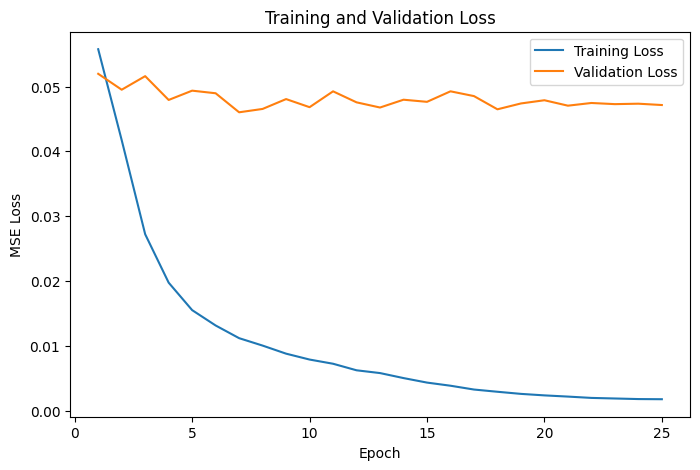

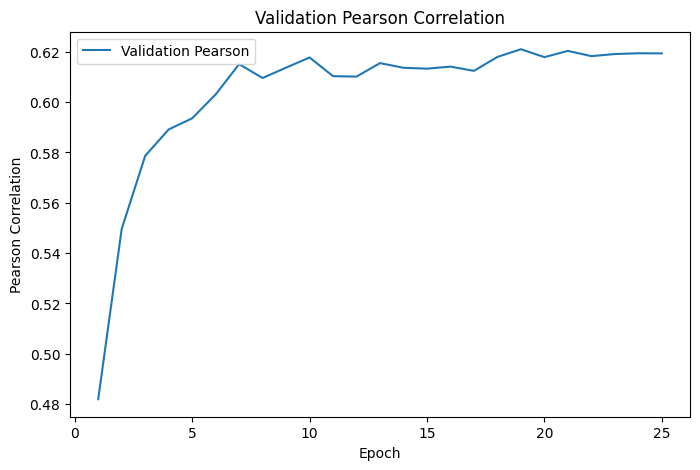

In [17]:
# 17. Plot Learning Curves

epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["train_loss"], label="Training Loss")
plt.plot(epochs_range, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["val_pearson"], label="Validation Pearson")
plt.xlabel("Epoch")
plt.ylabel("Pearson Correlation")
plt.title("Validation Pearson Correlation")
plt.legend()
plt.show()


In [18]:
# 18. Final Validation Evaluation

val_loss, val_pearson, val_rmse_value = evaluate_model(
    model, val_loader, criterion
)

print(f"Validation Loss    : {val_loss:.4f}")
print(f"Validation Pearson : {val_pearson:.4f}")
print(f"Validation RMSE    : {val_rmse_value:.4f}")


Validation Loss    : 0.0474
Validation Pearson : 0.6210
Validation RMSE    : 0.2177


## (a) / (b) Main experiment: 4 heads, final setting

Sections 16–18 above train the model defined in Section 12 (`NHEAD = 4`), plot the training/validation loss and validation Pearson curves, and report validation Pearson and RMSE for the best-Pearson checkpoint.

**Discussion (a)/(b).** [fill in after running: the loss values at the first and last epoch, whether validation loss rises again (overfitting), the epoch with the best Pearson, and the final Val Pearson / RMSE.]

In [19]:
# 19. Generate Submission

model.eval()

test_predictions = []
test_ids = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        predictions = model(input_ids, attention_mask)

        test_predictions.extend(predictions.cpu().numpy().tolist())
        test_ids.extend(list(batch["id"]))

# Create submission DataFrame
submission = pd.DataFrame({
    "id": test_ids,
    "score": test_predictions
})

# Check that IDs match the original test data
assert len(submission) == len(test_df)
assert submission["id"].tolist() == test_df["id"].tolist()

# Save submission file
submission.to_csv("submission.csv", index=False)

print("submission.csv has been generated successfully.")
print(submission.head())

submission.csv has been generated successfully.
                 id     score
0  56c8cc4180a9ea16  0.898738
1  d432a6416712e59a  0.208315
2  e7ab59f580fd7184  0.000073
3  03ab2935bce8a3eb  0.663920
4  494f877d48deb27f  0.000659


In [20]:
# Helper for the extra experiments in (c) and (d).
# It only CALLS the provided TransformerRegressor / train_model / evaluate_model
# and the build_optimizer / build_scheduler functions defined in the TODO blocks.
import time

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def run_config(name, nhead=4, dim_feedforward=256, dropout=0.2, lr=1e-3, weight_decay=1e-4,
               epochs=10, scheduler="none", warmup_epochs=2, pooling="mean",
               input_ln=False, rel_pos=False, emb_lr_mult=1.0, mlp_feats=None):
    global USE_INPUT_LAYERNORM, USE_REL_POS_BIAS
    saved = (USE_INPUT_LAYERNORM, USE_REL_POS_BIAS)
    USE_INPUT_LAYERNORM, USE_REL_POS_BIAS = input_ln, rel_pos   # read when the layers are built
    set_seed(SEED)
    m = TransformerRegressor(
        vocab_size=len(vocab),
        embedding_dim=EMBEDDING_DIM,
        pad_idx=PAD_IDX,
        nhead=nhead,
        num_layers=NUM_LAYERS,
        dim_feedforward=dim_feedforward,
        dropout=dropout,
        max_len=MAX_LEN,
    ).to(device)
    USE_INPUT_LAYERNORM, USE_REL_POS_BIAS = saved
    m.pooling_strategy = pooling
    if mlp_feats is not None:
        m.pool_mlp_features = list(mlp_feats)
    opt = build_optimizer(m, lr=lr, weight_decay=weight_decay, emb_lr_mult=emb_lr_mult)
    sch = build_scheduler(opt, kind=scheduler, epochs=epochs, warmup_epochs=warmup_epochs)

    print(f"===== {name} =====")
    t0 = time.perf_counter()
    hist = train_model(m, train_loader, val_loader, criterion, opt, epochs, scheduler=sch)
    seconds = time.perf_counter() - t0
    _, p, r = evaluate_model(m, val_loader, criterion)   # best-Pearson checkpoint
    return {
        "config": name, "nhead": nhead, "dim_ff": dim_feedforward, "dropout": dropout, "lr": lr,
        "weight_decay": weight_decay, "epochs": epochs, "scheduler": scheduler, "pooling": pooling,
        "input_ln": input_ln, "rel_pos": rel_pos, "emb_lr_mult": emb_lr_mult,
        "mlp_feats": ",".join(mlp_feats) if mlp_feats else "",
        "best_val_pearson": round(p, 4), "val_rmse": round(r, 4),
        "best_epoch": int(np.argmax(hist["val_pearson"])) + 1, "train_time_s": round(seconds, 1),
        "history": hist,
    }

## (c) Number of attention heads: 1 vs 4 vs 8

Same data split, same seed, same training budget, and the same default baseline setting: masked mean pooling, AdamW (lr 1e-3, weight decay 1e-4), no scheduler, 10 epochs. Only `nhead` changes, so head_dim is 128, 32 or 16.

===== heads=1 =====
Epoch 01/10 | Train Loss: 0.0674 | Val Loss: 0.0656 | Val Pearson: 0.1483 | Val RMSE: 0.2561
Epoch 02/10 | Train Loss: 0.0653 | Val Loss: 0.0649 | Val Pearson: 0.1690 | Val RMSE: 0.2547
Epoch 03/10 | Train Loss: 0.0642 | Val Loss: 0.0646 | Val Pearson: 0.1770 | Val RMSE: 0.2542
Epoch 04/10 | Train Loss: 0.0626 | Val Loss: 0.0650 | Val Pearson: 0.1949 | Val RMSE: 0.2549
Epoch 05/10 | Train Loss: 0.0615 | Val Loss: 0.0659 | Val Pearson: 0.2010 | Val RMSE: 0.2567
Epoch 06/10 | Train Loss: 0.0600 | Val Loss: 0.0650 | Val Pearson: 0.2468 | Val RMSE: 0.2550
Epoch 07/10 | Train Loss: 0.0585 | Val Loss: 0.0626 | Val Pearson: 0.2862 | Val RMSE: 0.2501
Epoch 08/10 | Train Loss: 0.0570 | Val Loss: 0.0615 | Val Pearson: 0.2962 | Val RMSE: 0.2480
Epoch 09/10 | Train Loss: 0.0555 | Val Loss: 0.0620 | Val Pearson: 0.3070 | Val RMSE: 0.2490
Epoch 10/10 | Train Loss: 0.0539 | Val Loss: 0.0612 | Val Pearson: 0.3282 | Val RMSE: 0.2474
===== heads=4 =====
Epoch 01/10 | Train Loss: 0.06

,config,nhead,head_dim,best_val_pearson,val_rmse,best_epoch,train_time_s
0,heads=1,1,128,0.3282,0.2474,10,74.6
1,heads=4,4,32,0.3173,0.2487,10,76.2
2,heads=8,8,16,0.2968,0.2491,10,76.1


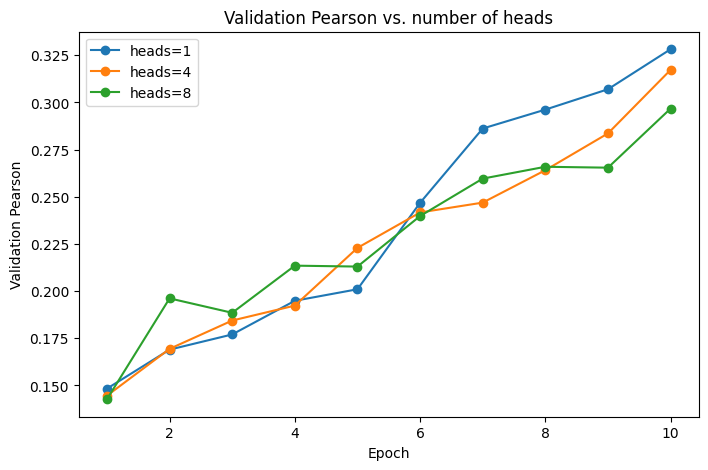

In [21]:
head_results = [run_config(f"heads={h}", nhead=h) for h in [1, 4, 8]]

head_table = pd.DataFrame([{k: v for k, v in r.items() if k != "history"} for r in head_results])
head_table.insert(2, "head_dim", EMBEDDING_DIM // head_table["nhead"])
display(head_table[["config", "nhead", "head_dim", "best_val_pearson", "val_rmse", "best_epoch", "train_time_s"]])

plt.figure(figsize=(8, 5))
for r in head_results:
    plt.plot(range(1, len(r["history"]["val_pearson"]) + 1), r["history"]["val_pearson"], marker="o", label=r["config"])
plt.xlabel("Epoch")
plt.ylabel("Validation Pearson")
plt.title("Validation Pearson vs. number of heads")
plt.legend()
plt.show()

**Discussion (c).** [fill in after running.] Points to cover:
* All three settings have the **same number of parameters**, because the Q/K/V/O projections are always 128×128. Only the split of the 128-dim space into heads changes (head_dim = 128 / 32 / 16).
* The inputs are very short (about 8 tokens on average), and the key signal is word-level matching between anchor and target. Few heads give each head a larger $d_k$ and therefore a richer similarity function. Many heads let the model attend to several relations at once, but each relation is computed in only 16 dimensions.
* Compare the best val Pearson / RMSE and the curves, and say whether the differences are larger than run-to-run noise, plus the time per run.

## (d) Tuning permitted settings

Every change uses only settings that live inside `TODO (Optional)` blocks: hyperparameters, the optimizer's weight decay, the learning-rate scheduler and the pooling strategy. Each row is trained from `SEED = 42`.

| ID | Change vs. previous row | Rationale |
|---|---|---|
| D0 | baseline: 4 heads, mean pooling, AdamW lr 1e-3, wd 1e-4, no scheduler, 10 epochs | reference |
| D1 | 25 epochs + 2-epoch linear warm-up + cosine decay + weight decay 1e-2 | the baseline is still improving at epoch 10; the schedule lets a longer run converge smoothly, and stronger weight decay counters overfitting |
| D2 | D1 + `interact` pooling (parameter-free) | explicit anchor-vs-target alignment (u⊙v) and difference (\|u−v\|) features instead of one global average |
| D3 | D2 + input LayerNorm in each encoder layer | the embedding is ~11× larger than the attention output, so without it the first attention sub-layer is almost ignored |
| D4 | D3 + relative-position bias in attention | the absolute sinusoidal signal is drowned by the large embedding; a learned per-head bias on j−i could restore position / segment-boundary information |
| D5 | D3 + 10× learning rate for the embedding | the embedding weights are ~N(0,1), so with lr 1e-3 an Adam step changes them by only ~0.1%; the embedding table holds most of the parameters and learns far too slowly |
| D6 | D3 + 30× learning rate for the embedding | is a larger multiplier better? |
| D7 | D5 + relative-position bias | does the bias help once the embedding learns properly? |
| D8 | D5 + `mlp` pooling | a learnable projection of the full interaction features [g, u, v, \|u−v\|, u⊙v] (5×128 → 128, GELU) instead of fixed 32/48/48 slices; its parameters are created inside the pooling `TODO (Optional)` block |
| D9 | D8 + dropout 0.1 | the learnable pooling head already regularises less than fixed slices; check whether dropout 0.2 is now too strong |
| D10 | D9 + 20× embedding learning rate (**final setting**) | with less dropout, a faster-learning embedding helps further |
| D11 | D10 + token-level alignment features (am, adf) in the `mlp` pooling | ESIM-style soft alignment compares anchor and target word by word instead of only through their averages |
| D12 | D10 + max-pooled anchor / target vectors (umax, vmax) | max pooling keeps the strongest individual word features that averaging dilutes |
| D13 | D10 + both | combination of D11 and D12 |

D3, D4 and D7 change only the inside of the `MyMultiheadAttention` / `MyTransformerEncoderLayer` classes, which are entirely `TODO` blocks. They are switched on and off with `USE_INPUT_LAYERNORM` / `USE_REL_POS_BIAS` in the hyperparameter cell. D5 and D6 change only the optimizer's parameter groups (`TODO` block of Section 14).

===== D0_baseline =====
Epoch 01/10 | Train Loss: 0.0674 | Val Loss: 0.0656 | Val Pearson: 0.1446 | Val RMSE: 0.2562
Epoch 02/10 | Train Loss: 0.0653 | Val Loss: 0.0648 | Val Pearson: 0.1694 | Val RMSE: 0.2546
Epoch 03/10 | Train Loss: 0.0642 | Val Loss: 0.0645 | Val Pearson: 0.1844 | Val RMSE: 0.2541
Epoch 04/10 | Train Loss: 0.0630 | Val Loss: 0.0645 | Val Pearson: 0.1923 | Val RMSE: 0.2541
Epoch 05/10 | Train Loss: 0.0620 | Val Loss: 0.0645 | Val Pearson: 0.2229 | Val RMSE: 0.2539
Epoch 06/10 | Train Loss: 0.0606 | Val Loss: 0.0640 | Val Pearson: 0.2417 | Val RMSE: 0.2531
Epoch 07/10 | Train Loss: 0.0597 | Val Loss: 0.0635 | Val Pearson: 0.2469 | Val RMSE: 0.2520
Epoch 08/10 | Train Loss: 0.0580 | Val Loss: 0.0637 | Val Pearson: 0.2641 | Val RMSE: 0.2524
Epoch 09/10 | Train Loss: 0.0570 | Val Loss: 0.0629 | Val Pearson: 0.2836 | Val RMSE: 0.2507
Epoch 10/10 | Train Loss: 0.0558 | Val Loss: 0.0618 | Val Pearson: 0.3173 | Val RMSE: 0.2487
===== D1_25ep_cosine_wd =====
Epoch 01/25 | Tr

,config,nhead,dim_ff,dropout,lr,weight_decay,epochs,scheduler,pooling,input_ln,rel_pos,emb_lr_mult,mlp_feats,best_val_pearson,val_rmse,best_epoch,train_time_s
0,D0_baseline,4,256,0.2,0.001,0.0001,10,none,mean,False,False,1.0,,0.3173,0.2487,10,76.2
1,D1_25ep_cosine_wd,4,256,0.2,0.001,0.0100,25,warmup_cosine,mean,False,False,1.0,,0.4196,0.2436,25,191.1
2,D2_+interact_pool,4,256,0.2,0.001,0.0100,25,warmup_cosine,interact,False,False,1.0,,0.4871,0.2568,24,202.0
3,D3_D2_+input_LN,4,256,0.2,0.001,0.0100,25,warmup_cosine,interact,True,False,1.0,,0.5175,0.2540,25,204.9
4,D4_D3_+rel_pos,4,256,0.2,0.001,0.0100,25,warmup_cosine,interact,True,True,1.0,,0.5260,0.2505,25,215.8
5,D5_D3_+emb_lr_x10,4,256,0.2,0.001,0.0100,25,warmup_cosine,interact,True,False,10.0,,0.5919,0.2267,22,204.6
6,D6_D3_+emb_lr_x30,4,256,0.2,0.001,0.0100,25,warmup_cosine,interact,True,False,30.0,,0.5965,0.2249,25,204.8
7,D7_D5_+rel_pos,4,256,0.2,0.001,0.0100,25,warmup_cosine,interact,True,True,10.0,,0.6001,0.2249,25,215.9
8,D8_D5_+mlp_pool,4,256,0.2,0.001,0.0100,25,warmup_cosine,mlp,True,False,10.0,,0.6161,0.2310,21,191.5
9,D9_D8_dropout0.1,4,256,0.1,0.001,0.0100,25,warmup_cosine,mlp,True,False,10.0,,0.6262,0.2143,20,193.2


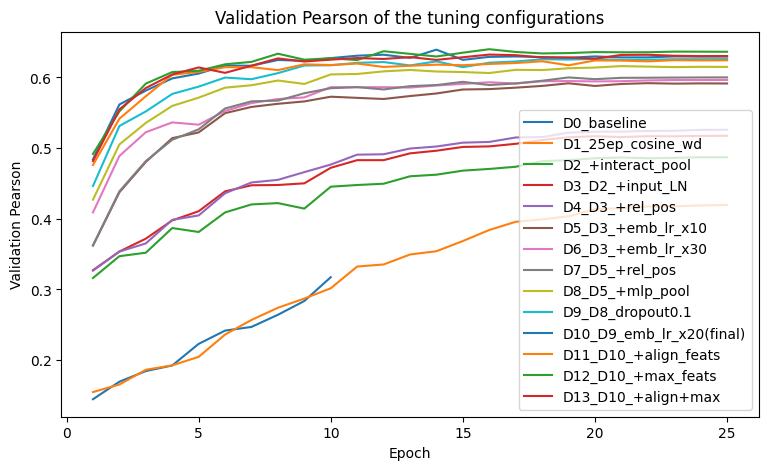

Best configuration on validation Pearson: D12_D10_+max_feats (0.6400)
Final model (Section 12) uses: pooling=mlp, epochs=25, scheduler=warmup_cosine, weight_decay=0.01, dropout=0.1, lr=0.001, dim_ff=256, input_LN=True, rel_pos=False, emb_lr_mult=20


In [22]:
D1 = dict(epochs=25, scheduler="warmup_cosine", warmup_epochs=2, weight_decay=1e-2)
tuning_configs = [
    dict(name="D0_baseline"),
    dict(name="D1_25ep_cosine_wd", **D1),
    dict(name="D2_+interact_pool", **D1, pooling="interact"),
    dict(name="D3_D2_+input_LN", **D1, pooling="interact", input_ln=True),
    dict(name="D4_D3_+rel_pos", **D1, pooling="interact", input_ln=True, rel_pos=True),
    dict(name="D5_D3_+emb_lr_x10", **D1, pooling="interact", input_ln=True, emb_lr_mult=10.0),
    dict(name="D6_D3_+emb_lr_x30", **D1, pooling="interact", input_ln=True, emb_lr_mult=30.0),
    dict(name="D7_D5_+rel_pos", **D1, pooling="interact", input_ln=True, rel_pos=True, emb_lr_mult=10.0),
    dict(name="D8_D5_+mlp_pool", **D1, pooling="mlp", input_ln=True, emb_lr_mult=10.0),
    dict(name="D9_D8_dropout0.1", **D1, pooling="mlp", input_ln=True, emb_lr_mult=10.0, dropout=0.1),
    dict(name="D10_D9_emb_lr_x20(final)", **D1, pooling="mlp", input_ln=True, emb_lr_mult=20.0, dropout=0.1),
    dict(name="D11_D10_+align_feats", **D1, pooling="mlp", input_ln=True, emb_lr_mult=20.0, dropout=0.1,
         mlp_feats=["g", "u", "v", "ad", "uv", "am", "adf"]),
    dict(name="D12_D10_+max_feats", **D1, pooling="mlp", input_ln=True, emb_lr_mult=20.0, dropout=0.1,
         mlp_feats=["g", "u", "v", "ad", "uv", "umax", "vmax"]),
    dict(name="D13_D10_+align+max", **D1, pooling="mlp", input_ln=True, emb_lr_mult=20.0, dropout=0.1,
         mlp_feats=["g", "u", "v", "ad", "uv", "am", "adf", "umax", "vmax"]),
]
tune_results = [run_config(**c) for c in tuning_configs]

tuning_table = pd.DataFrame([{k: v for k, v in r.items() if k != "history"} for r in tune_results])
display(tuning_table)

plt.figure(figsize=(9, 5))
for r in tune_results:
    plt.plot(range(1, len(r["history"]["val_pearson"]) + 1), r["history"]["val_pearson"], label=r["config"])
plt.xlabel("Epoch")
plt.ylabel("Validation Pearson")
plt.title("Validation Pearson of the tuning configurations")
plt.legend()
plt.show()

best = max(tune_results, key=lambda r: r["best_val_pearson"])
print(f"Best configuration on validation Pearson: {best['config']} ({best['best_val_pearson']:.4f})")
print("Final model (Section 12) uses: pooling=%s, epochs=%d, scheduler=%s, weight_decay=%g, dropout=%g, lr=%g, dim_ff=%d, input_LN=%s, rel_pos=%s, emb_lr_mult=%g"
      % (POOLING_STRATEGY, EPOCHS, SCHEDULER_TYPE, WEIGHT_DECAY, DROPOUT, LEARNING_RATE, DIM_FEEDFORWARD,
         USE_INPUT_LAYERNORM, USE_REL_POS_BIAS, EMB_LR_MULT))

**Discussion (d).** [fill in after running: the gain of each row over the previous one, and why.] Points to cover:
* **D1** (longer budget + warm-up/cosine + weight decay): the baseline curve is still rising at epoch 10, so a longer, smoothly decaying schedule should help. The provided `train_model` keeps the best-Pearson checkpoint, so overfitting in late epochs does not hurt the selected model.
* **D2** (pooling): mean pooling mixes context, anchor and target into one vector, so the regression head cannot tell which phrase a feature came from. `interact` exposes the alignment u⊙v and the difference |u−v| directly, without any extra parameters.
* **D3 / D4** (encoder-side changes inside the TODO classes): the input LayerNorm lets the first attention sub-layer contribute; the relative-position bias is an attempt to restore the order information that the large embedding scale hides.
* **D5 / D6** (optimizer parameter groups): a larger embedding learning rate lets the ~1M embedding weights move at a useful speed. Compare 10× and 30× to see whether the multiplier is too large.
* **D7**: checks whether the relative-position bias helps on top of D5.
* **D8** (`mlp` pooling): the fixed slices of `interact` let the linear head see only 32/48/48 dimensions of g, u⊙v and |u−v|. The small learnable projection sees all of [g, u, v, |u−v|, u⊙v] and combines them non-linearly before the provided regression head.
* **D9** (dropout 0.1): checks the regularisation strength with the learnable pooling head.
* **D10** (20× embedding learning rate): re-tunes the embedding learning rate on top of D9.
* **D11–D13** (richer `mlp` pooling inputs): token-level alignment features and max pooling, all computed inside the pooling TODO block. If one of them beats D10, set `POOL_MLP_FEATURES` in Section 12 to that row's feature list.
* The final model in Section 12 uses the configuration with the best validation Pearson. If the table selects a different row from D10, copy that row's values into the `TODO (Optional)` block of Section 12 and re-run.

## (e) Final model: ensemble of the final configuration

The final model is an **ensemble of `N_ENSEMBLE` = 8 models with the Section 12 configuration**. It is a heterogeneous ensemble: the members cycle through the Section 12 pooling features plus every richer `mlp` feature set from (d) (D11–D13) whose validation Pearson is within 0.01 of the best configuration. The selection is automatic, from the (d) table. The first member is the `model` trained in Section 16. The other members are trained here with the provided `TransformerRegressor` and `train_model` and the `build_optimizer` / `build_scheduler` defined in the TODO blocks. No provided code is changed.

The random seed is **not** reset between members. Every member continues the same `SEED = 42` random stream (initialisation, shuffling, dropout), so the members differ from each other but the whole notebook stays reproducible. Their sigmoid outputs are averaged. Averaging reduces the variance of small models trained from scratch, which typically raises Pearson by a few hundredths.

The ensemble's `submission.csv` overwrites the single-model file written in Section 19. The test IDs are taken from `test_loader` in the original `test.csv` order, and the same assertions as Section 19 check this.

In [ ]:
N_ENSEMBLE = 8   # more members -> lower variance (each extra member costs one more training run)

# Heterogeneous ensemble: besides the Section 12 pooling features, also use every
# "mlp" pooling feature set from (d) whose validation Pearson is within 0.01 of the
# best (D11-D13). Different pooling inputs make the members' errors less correlated,
# which helps averaging. Members cycle through these feature sets.
ENSEMBLE_FEATURE_SETS = [list(POOL_MLP_FEATURES)]
if "tune_results" in globals():
    best_p = max(r["best_val_pearson"] for r in tune_results)
    for r in tune_results:
        if r["pooling"] == "mlp" and r["mlp_feats"] and r["best_val_pearson"] >= best_p - 0.01:
            fs = r["mlp_feats"].split(",")
            if fs not in ENSEMBLE_FEATURE_SETS:
                ENSEMBLE_FEATURE_SETS.append(fs)
print("Ensemble pooling feature sets:", ENSEMBLE_FEATURE_SETS)

def train_member(k):
    # Same configuration as the Section 12 model except for the pooling feature
    # set (cycled over ENSEMBLE_FEATURE_SETS). The seed is NOT reset, so the
    # RNG stream continues and every member gets a different initialisation /
    # shuffle / dropout pattern.
    m = TransformerRegressor(
        vocab_size=len(vocab),
        embedding_dim=EMBEDDING_DIM,
        pad_idx=PAD_IDX,
        nhead=NHEAD,
        num_layers=NUM_LAYERS,
        dim_feedforward=DIM_FEEDFORWARD,
        dropout=DROPOUT,
        max_len=MAX_LEN,
    ).to(device)
    m.pool_mlp_features = ENSEMBLE_FEATURE_SETS[k % len(ENSEMBLE_FEATURE_SETS)]
    opt = build_optimizer(m)
    sch = build_scheduler(opt)
    print(f"===== ensemble member {k} | pooling features {m.pool_mlp_features} =====")
    train_model(m, train_loader, val_loader, criterion, opt, EPOCHS, scheduler=sch)
    return m

@torch.no_grad()
def predict_loader(m, loader):
    m.eval()
    preds, ids = [], []
    for batch in loader:
        preds.append(m(batch["input_ids"].to(device), batch["attention_mask"].to(device)).cpu().numpy())
        ids.extend(list(batch["id"]))
    return np.concatenate(preds), ids

members = [model] + [train_member(k) for k in range(1, N_ENSEMBLE)]

y_val = val_df["score"].values
val_preds = np.stack([predict_loader(m, val_loader)[0] for m in members])
for k, p in enumerate(val_preds):
    print(f"member {k}: Val Pearson = {pearson_corr(y_val, p):.4f} | Val RMSE = {rmse(y_val, p):.4f}")
ens_val = val_preds.mean(0)
print(f"ENSEMBLE ({len(members)} models): Val Pearson = {pearson_corr(y_val, ens_val):.4f} | Val RMSE = {rmse(y_val, ens_val):.4f}")

Ensemble pooling feature sets: [['g', 'u', 'v', 'ad', 'uv'], ['g', 'u', 'v', 'ad', 'uv', 'umax', 'vmax'], ['g', 'u', 'v', 'ad', 'uv', 'am', 'adf', 'umax', 'vmax']]
===== ensemble member 1 | pooling features ['g', 'u', 'v', 'ad', 'uv', 'umax', 'vmax'] =====
Epoch 01/25 | Train Loss: 0.0554 | Val Loss: 0.0502 | Val Pearson: 0.5043 | Val RMSE: 0.2240
Epoch 02/25 | Train Loss: 0.0411 | Val Loss: 0.0474 | Val Pearson: 0.5577 | Val RMSE: 0.2178
Epoch 03/25 | Train Loss: 0.0265 | Val Loss: 0.0490 | Val Pearson: 0.5831 | Val RMSE: 0.2214
Epoch 04/25 | Train Loss: 0.0187 | Val Loss: 0.0451 | Val Pearson: 0.6042 | Val RMSE: 0.2123
Epoch 05/25 | Train Loss: 0.0150 | Val Loss: 0.0462 | Val Pearson: 0.6107 | Val RMSE: 0.2149
Epoch 06/25 | Train Loss: 0.0123 | Val Loss: 0.0547 | Val Pearson: 0.6012 | Val RMSE: 0.2338
Epoch 07/25 | Train Loss: 0.0104 | Val Loss: 0.0453 | Val Pearson: 0.6195 | Val RMSE: 0.2128
Epoch 08/25 | Train Loss: 0.0091 | Val Loss: 0.0471 | Val Pearson: 0.6262 | Val RMSE: 0.2170

In [ ]:
# Ensemble submission (same format and ID checks as Section 19)
test_preds = []
for m in members:
    p, ids_ = predict_loader(m, test_loader)
    test_preds.append(p)
test_ids = ids_

submission = pd.DataFrame({
    "id": test_ids,
    "score": np.stack(test_preds).mean(0).tolist()
})

assert len(submission) == len(test_df)
assert submission["id"].tolist() == test_df["id"].tolist()

submission.to_csv("submission.csv", index=False)
print("Ensemble submission.csv has been generated successfully.")
print(submission.head())
print(submission["score"].describe())

## Kaggle submission

The `submission.csv` written by the ensemble cell above is the file that was uploaded. It covers all 7,295 test rows, in the original ID order.

**Final Kaggle leaderboard score: 0.68679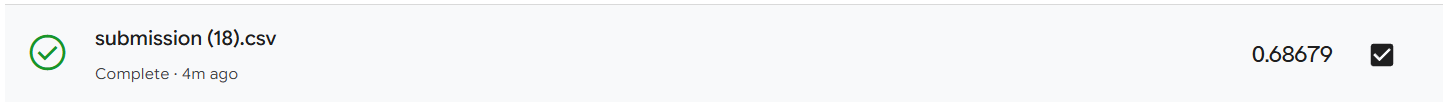**